In [1]:
import numpy as np

In [2]:
import pandas as pd

In [3]:
df=pd.read_csv('customer_churn.csv')

In [4]:
df

,Names,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Onboard_date,Location,Company,Churn
0,Cameron Williams,42.0,11066.80,0,7.22,8.0,2013-08-30 07:00:40,"10265 Elizabeth Mission Barkerburgh, AK 89518",Harvey LLC,1
1,Kevin Mueller,41.0,11916.22,0,6.50,11.0,2013-08-13 00:38:46,"6157 Frank Gardens Suite 019 Carloshaven, RI 1...",Wilson PLC,1
2,Eric Lozano,38.0,12884.75,0,6.67,12.0,2016-06-29 06:20:07,"1331 Keith Court Alyssahaven, DE 90114","Miller, Johnson and Wallace",1
3,Phillip White,42.0,8010.76,0,6.71,10.0,2014-04-22 12:43:12,"13120 Daniel Mount Angelabury, WY 30645-4695",Smith Inc,1
4,Cynthia Norton,37.0,9191.58,0,5.56,9.0,2016-01-19 15:31:15,"765 Tricia Row Karenshire, MH 71730",Love-Jones,1
...,...,...,...,...,...,...,...,...,...,...
895,Paul Miller,42.0,12800.82,1,3.62,8.0,2007-12-01 13:29:34,"9316 Julian Fort Suite 328 North Leslie, ME 43961",Evans-Lucero,0
896,Natalie Hodges,52.0,9893.92,0,6.91,7.0,2008-12-28 15:23:58,"8419 William Square Apt. 695 Martinville, RI 3...",Perry and Sons,0
897,Ana Smith,45.0,12056.18,0,5.46,4.0,2014-06-20 05:10:09,Unit 8633 Box 8738 DPO AA 14126-5026,Schneider-Smith,0
898,Justin Leonard,51.0,6517.93,1,5.47,10.0,2012-05-30 00:15:43,"49800 Torres Ways Suite 886 West Bradleybury, ...",Robles-Abbott,0


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (900, 10)

Column names:
['Names', 'Age', 'Total_Purchase', 'Account_Manager', 'Years', 'Num_Sites', 'Onboard_date', 'Location', 'Company', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Names            900 non-null    object 
 1   Age              900 non-null    float64
 2   Total_Purchase   900 non-null    float64
 3   Account_Manager  900 non-null    int64  
 4   Years            900 non-null    float64
 5   Num_Sites        900 non-null    float64
 6   Onboard_date     900 non-null    object 
 7   Location         900 non-null    object 
 8   Company          900 non-null    object 
 9   Churn            900 non-null    int64  
dtypes: float64(4), int64(2), object(4)
memory usage: 70.4+ KB

Missing values:
Names              0
Age                0
Total_Purchase     0
Account_Manage

In [6]:
df.describe()

,Age,Total_Purchase,Account_Manager,Years,Num_Sites,Churn
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,41.816667,10062.824033,0.481111,5.273156,8.587778,0.166667
std,6.127560,2408.644532,0.499921,1.274449,1.764836,0.372885
min,22.000000,100.000000,0.000000,1.000000,3.000000,0.000000
25%,38.000000,8497.122500,0.000000,4.450000,7.000000,0.000000
50%,42.000000,10045.870000,0.000000,5.215000,8.000000,0.000000
75%,46.000000,11760.105000,1.000000,6.110000,10.000000,0.000000
max,65.000000,18026.010000,1.000000,9.150000,14.000000,1.000000


In [9]:
print(df.columns.tolist())

['Names', 'Age', 'Total_Purchase', 'Account_Manager', 'Years', 'Num_Sites', 'Onboard_date', 'Location', 'Company', 'Churn']


In [10]:
print(df.isnull().sum())


Names              0
Age                0
Total_Purchase     0
Account_Manager    0
Years              0
Num_Sites          0
Onboard_date       0
Location           0
Company            0
Churn              0
dtype: int64


In [11]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
print(df["Churn"].value_counts())

Churn
0    750
1    150
Name: count, dtype: int64


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

Churn
0    750
1    150
Name: count, dtype: int64


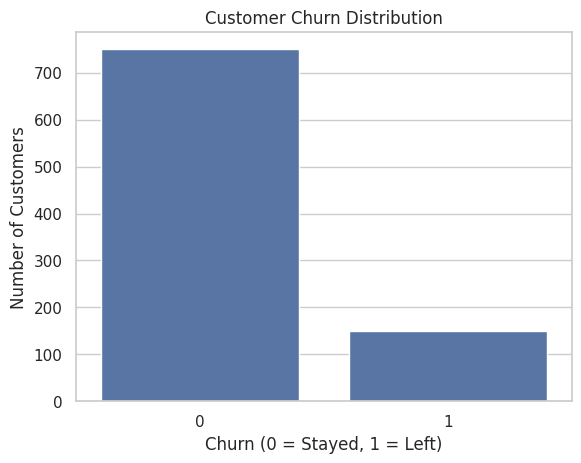

In [14]:
print(df["Churn"].value_counts())

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")
plt.show()

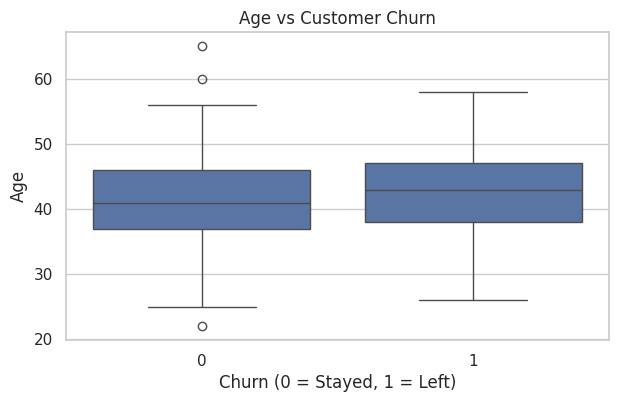

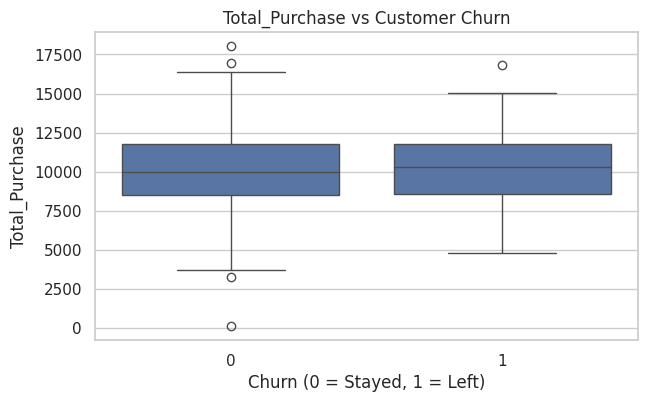

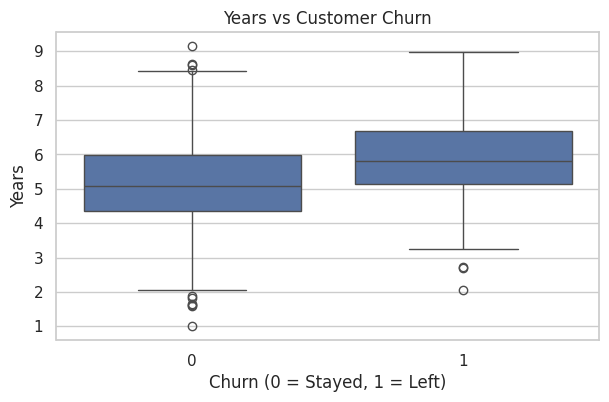

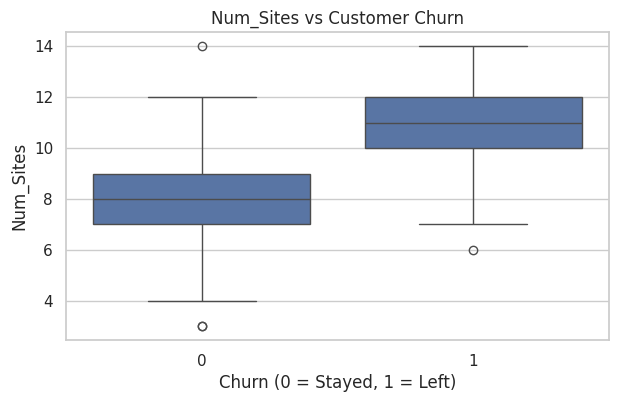

In [15]:
features = ["Age", "Total_Purchase", "Years", "Num_Sites"]

for feature in features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(data=df, x="Churn", y=feature)

    plt.title(f"{feature} vs Customer Churn")
    plt.xlabel("Churn (0 = Stayed, 1 = Left)")
    plt.ylabel(feature)

    plt.show()

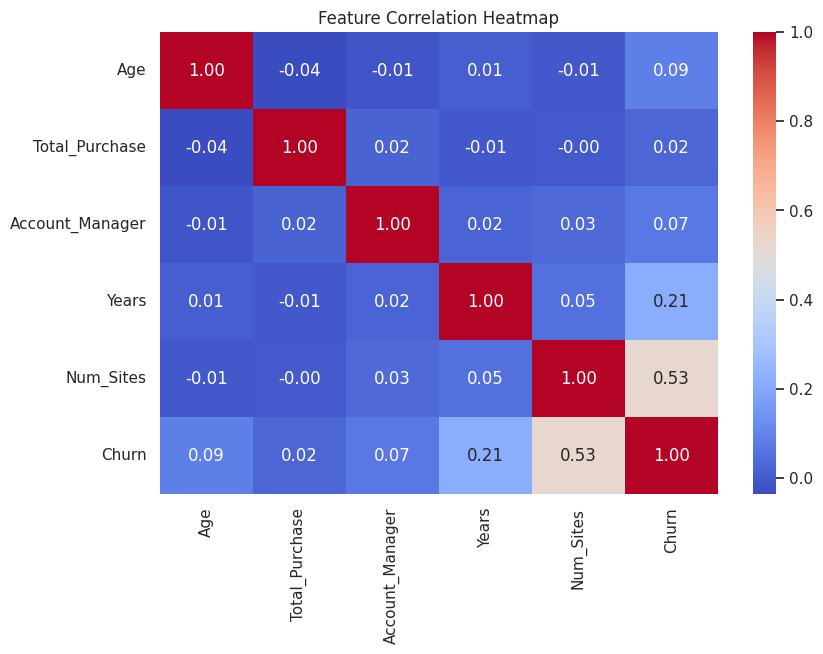

In [16]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [17]:
# Remove columns that are identifiers or not useful in our baseline model
df_model = df.drop(columns=["Names", "Onboard_date", "Location", "Company"],
                   errors="ignore")

# Separate input features and target
X = df_model.drop("Churn", axis=1)
y = df_model["Churn"]

print("Features:", X.columns.tolist())
print("Target distribution:")
print(y.value_counts())

Features: ['Age', 'Total_Purchase', 'Account_Manager', 'Years', 'Num_Sites']
Target distribution:
Churn
0    750
1    150
Name: count, dtype: int64


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 720
Testing samples: 180


In [19]:
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data shape: (720, 5)
Testing data shape: (180, 5)

Training target distribution:
Churn
0    600
1    120
Name: count, dtype: int64

Testing target distribution:
Churn
0    150
1     30
Name: count, dtype: int64


In [52]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Create the model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [53]:
# Predict churn for unseen customers
y_pred = model.predict(X_test)

print("Actual values:     ", y_test.iloc[:10].tolist())
print("Predicted values:  ", y_pred[:10])

Actual values:      [0, 0, 0, 0, 0, 0, 0, 1, 0, 0]
Predicted values:   [0 0 0 0 0 0 0 0 0 0]


In [54]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

Model Accuracy: 86.67%


              precision    recall  f1-score   support

           0       0.89      0.96      0.92       150
           1       0.67      0.40      0.50        30

    accuracy                           0.87       180
   macro avg       0.78      0.68      0.71       180
weighted avg       0.85      0.87      0.85       180



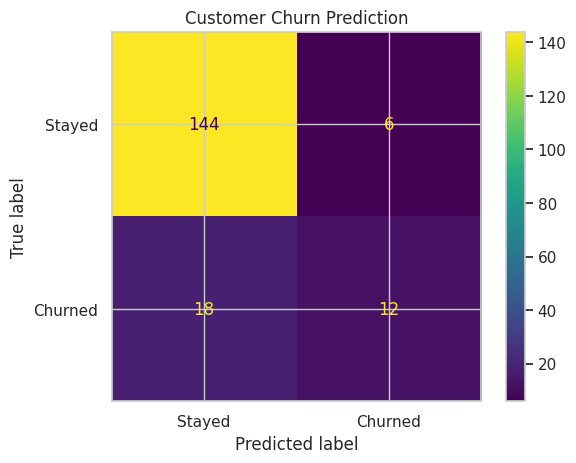

In [91]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Detailed evaluation
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot()
plt.title("Customer Churn Prediction")
plt.show()

In [56]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Create a pipeline
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [57]:
# Predict on test data
lr_pred = lr_model.predict(X_test)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, lr_pred)

print(f"Logistic Regression Accuracy: {lr_accuracy * 100:.2f}%")

Logistic Regression Accuracy: 86.67%


In [58]:
rf_pred = model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")
print(f"Logistic Regression Accuracy: {lr_accuracy * 100:.2f}%")

Random Forest Accuracy: 86.67%
Logistic Regression Accuracy: 86.67%


In [59]:
from sklearn.metrics import classification_report

print("RANDOM FOREST")
print(classification_report(y_test, rf_pred, zero_division=0))

print("\nLOGISTIC REGRESSION")
print(classification_report(y_test, lr_pred, zero_division=0))

RANDOM FOREST
              precision    recall  f1-score   support

           0       0.89      0.96      0.92       150
           1       0.67      0.40      0.50        30

    accuracy                           0.87       180
   macro avg       0.78      0.68      0.71       180
weighted avg       0.85      0.87      0.85       180


LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       0.96      0.87      0.92       150
           1       0.57      0.83      0.68        30

    accuracy                           0.87       180
   macro avg       0.77      0.85      0.80       180
weighted avg       0.90      0.87      0.88       180



In [60]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create SVM pipeline
svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", class_weight="balanced")
)

# Train the model
svm_model.fit(X_train, y_train)

print("SVM model training completed!")

SVM model training completed!


In [61]:
from sklearn.metrics import accuracy_score

# Predict on test data
svm_pred = svm_model.predict(X_test)

# Calculate accuracy
svm_accuracy = accuracy_score(y_test, svm_pred)

print(f"SVM Accuracy: {svm_accuracy * 100:.2f}%")

SVM Accuracy: 85.56%


              precision    recall  f1-score   support

           0       0.95      0.87      0.91       150
           1       0.55      0.77      0.64        30

    accuracy                           0.86       180
   macro avg       0.75      0.82      0.77       180
weighted avg       0.88      0.86      0.86       180



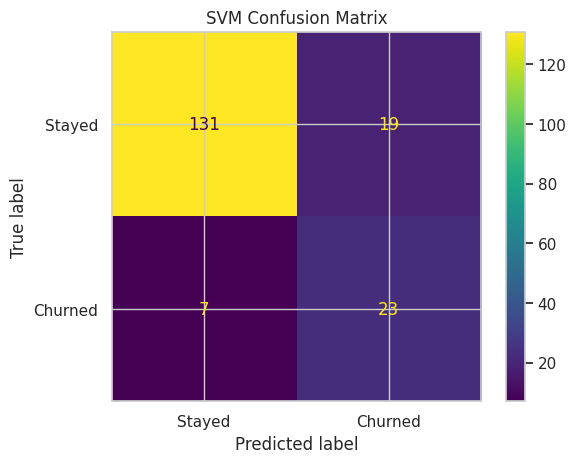

In [62]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print(classification_report(y_test, svm_pred, zero_division=0))

cm = confusion_matrix(y_test, svm_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot()
plt.title("SVM Confusion Matrix")
plt.show()

In [63]:
from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create individual models
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    )
)

svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        class_weight="balanced"
    )
)

# Combine the models
ensemble_model = VotingClassifier(
    estimators=[
        ("random_forest", rf),
        ("logistic_regression", lr),
        ("svm", svm)
    ],
    voting="hard"
)

# Train the ensemble
ensemble_model.fit(X_train, y_train)

print("Ensemble model trained successfully!")

Ensemble model trained successfully!


Ensemble Accuracy: 87.22%

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.89      0.92       150
           1       0.59      0.77      0.67        30

    accuracy                           0.87       180
   macro avg       0.77      0.83      0.79       180
weighted avg       0.89      0.87      0.88       180



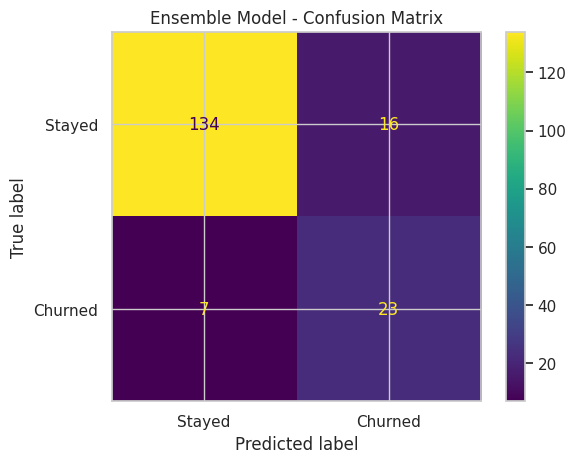

In [64]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict on unseen test data
ensemble_pred = ensemble_model.predict(X_test)

# Calculate accuracy
ensemble_accuracy = accuracy_score(y_test, ensemble_pred)

print(f"Ensemble Accuracy: {ensemble_accuracy * 100:.2f}%")

# Detailed evaluation
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        ensemble_pred,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, ensemble_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Churned"]
)

disp.plot()
plt.title("Ensemble Model - Confusion Matrix")
plt.show()

In [65]:
results = {
    "Random Forest": accuracy_score(y_test, model.predict(X_test)),
    "Logistic Regression": accuracy_score(y_test, lr_model.predict(X_test)),
    "SVM": accuracy_score(y_test, svm_model.predict(X_test)),
    "Ensemble": accuracy_score(y_test, ensemble_pred)
}

print("MODEL COMPARISON\n")

for name, score in results.items():
    print(f"{name}: {score * 100:.2f}%")

MODEL COMPARISON

Random Forest: 86.67%
Logistic Regression: 86.67%
SVM: 85.56%
Ensemble: 87.22%


In [66]:
from sklearn.ensemble import GradientBoostingClassifier

# Create the model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

print("Gradient Boosting training completed!")

Gradient Boosting training completed!


In [67]:
from sklearn.metrics import accuracy_score

# Predict on test data
gb_pred = gb_model.predict(X_test)

# Calculate accuracy
gb_accuracy = accuracy_score(y_test, gb_pred)

print(f"Gradient Boosting Accuracy: {gb_accuracy * 100:.2f}%")

Gradient Boosting Accuracy: 88.89%


              precision    recall  f1-score   support

      Stayed       0.92      0.95      0.93       150
     Churned       0.71      0.57      0.63        30

    accuracy                           0.89       180
   macro avg       0.81      0.76      0.78       180
weighted avg       0.88      0.89      0.88       180



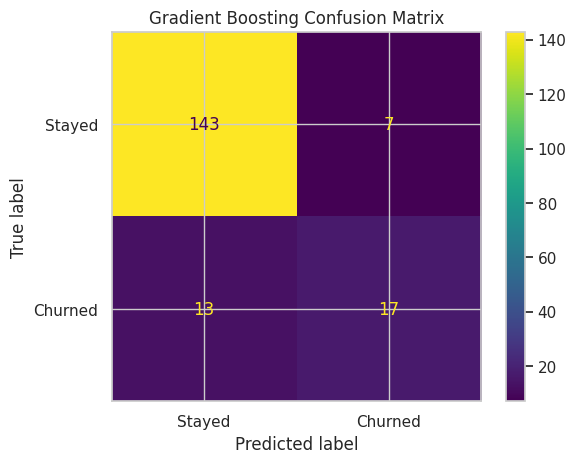

In [68]:
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print(classification_report(
    y_test,
    gb_pred,
    target_names=["Stayed", "Churned"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    gb_pred,
    display_labels=["Stayed", "Churned"]
)

plt.title("Gradient Boosting Confusion Matrix")
plt.show()

In [69]:
%pip install -q xgboost

In [70]:
from xgboost import XGBClassifier

# Calculate class imbalance ratio from training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

# Create XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=negative_count / positive_count,
    eval_metric="logloss",
    random_state=42
)

# Train the model
xgb_model.fit(X_train, y_train)

print("XGBoost training completed successfully!")

XGBoost training completed successfully!


In [71]:
from sklearn.metrics import accuracy_score

# Predict on test data
xgb_pred = xgb_model.predict(X_test)

# Calculate accuracy
xgb_accuracy = accuracy_score(y_test, xgb_pred)

print(f"XGBoost Accuracy: {xgb_accuracy * 100:.2f}%")

XGBoost Accuracy: 85.00%


XGBOOST CLASSIFICATION REPORT

              precision    recall  f1-score   support

      Stayed       0.92      0.90      0.91       150
     Churned       0.55      0.60      0.57        30

    accuracy                           0.85       180
   macro avg       0.73      0.75      0.74       180
weighted avg       0.86      0.85      0.85       180


Confusion Matrix:
[[147   3]
 [ 14  16]]

ROC-AUC: 0.914


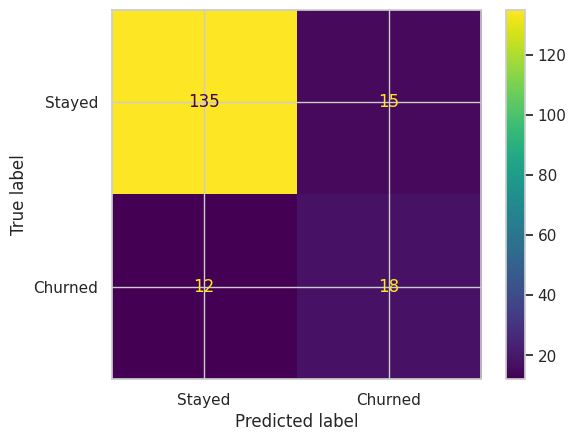

In [92]:
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

print("XGBOOST CLASSIFICATION REPORT\n")

print(
    classification_report(
        y_test,
        xgb_pred,
        target_names=["Stayed", "Churned"],
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_pred,
    display_labels=["Stayed", "Churned"]
)

plt.title("XGBoost Confusion Matrix")
plt.show()

In [73]:
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

models = {
    "Random Forest": model,
    "Logistic Regression": lr_model,
    "SVM": svm_model,
    "Voting Ensemble": ensemble_model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model
}

for name, clf in models.items():
    predictions = clf.predict(X_test)

    print(f"\n{name}")
    print(f"Accuracy:  {accuracy_score(y_test, predictions):.3f}")
    print(f"Precision: {precision_score(y_test, predictions, zero_division=0):.3f}")
    print(f"Recall:    {recall_score(y_test, predictions, zero_division=0):.3f}")
    print(f"F1-score:  {f1_score(y_test, predictions, zero_division=0):.3f}")


Random Forest
Accuracy:  0.867
Precision: 0.667
Recall:    0.400
F1-score:  0.500

Logistic Regression
Accuracy:  0.867
Precision: 0.568
Recall:    0.833
F1-score:  0.676

SVM
Accuracy:  0.856
Precision: 0.548
Recall:    0.767
F1-score:  0.639

Voting Ensemble
Accuracy:  0.872
Precision: 0.590
Recall:    0.767
F1-score:  0.667

Gradient Boosting
Accuracy:  0.889
Precision: 0.708
Recall:    0.567
F1-score:  0.630

XGBoost
Accuracy:  0.850
Precision: 0.545
Recall:    0.600
F1-score:  0.571


In [74]:

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Create the model
extra_model = ExtraTreesClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
extra_model.fit(X_train, y_train)

# Make predictions
y_pred_extra = extra_model.predict(X_test)

# Evaluate
print("Extra Trees Accuracy:",
      accuracy_score(y_test, y_pred_extra))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_extra))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_extra))

# ROC-AUC for binary classification
y_prob_extra = extra_model.predict_proba(X_test)[:, 1]
print("\nROC-AUC:",
      roc_auc_score(y_test, y_prob_extra))


Extra Trees Accuracy: 0.8777777777777778

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.97      0.93       150
           1       0.72      0.43      0.54        30

    accuracy                           0.88       180
   macro avg       0.81      0.70      0.74       180
weighted avg       0.87      0.88      0.86       180


Confusion Matrix:
[[145   5]
 [ 17  13]]

ROC-AUC: 0.8777777777777778


In [75]:

from sklearn.ensemble import StackingClassifier, ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Base models
base_models = [
    ("lr", LogisticRegression(max_iter=2000)),
    ("svm", SVC(probability=True, random_state=42)),
    ("extra", ExtraTreesClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
]

# Meta-model
meta_model = LogisticRegression(max_iter=2000)

# Stacking classifier
stack_model = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=5,
    stack_method="auto",
    n_jobs=-1
)

# Train
stack_model.fit(X_train, y_train)

# Predict
y_pred_stack = stack_model.predict(X_test)
y_prob_stack = stack_model.predict_proba(X_test)[:, 1]

# Evaluation
print("Stacking Accuracy:",
      accuracy_score(y_test, y_pred_stack))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_stack))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_stack))

print("\nROC-AUC:",
      roc_auc_score(y_test, y_prob_stack))


Stacking Accuracy: 0.9055555555555556

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.98      0.95       150
           1       0.84      0.53      0.65        30

    accuracy                           0.91       180
   macro avg       0.88      0.76      0.80       180
weighted avg       0.90      0.91      0.90       180


Confusion Matrix:
[[147   3]
 [ 14  16]]

ROC-AUC: 0.914


In [76]:

%pip install -q catboost


In [77]:

from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

cat_model = CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)

cat_model.fit(X_train, y_train)

y_pred_cat = cat_model.predict(X_test).ravel()
y_prob_cat = cat_model.predict_proba(X_test)[:, 1]

print("CatBoost Accuracy:",
      accuracy_score(y_test, y_pred_cat))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_cat))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_cat))

print("\nROC-AUC:",
      roc_auc_score(y_test, y_prob_cat))


0:	total: 11.6ms	remaining: 5.8s
100:	total: 678ms	remaining: 2.68s
200:	total: 1.4s	remaining: 2.08s
300:	total: 2.47s	remaining: 1.63s
400:	total: 3.06s	remaining: 757ms
499:	total: 3.84s	remaining: 0us
CatBoost Accuracy: 0.8722222222222222

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.93      0.92       150
           1       0.63      0.57      0.60        30

    accuracy                           0.87       180
   macro avg       0.77      0.75      0.76       180
weighted avg       0.87      0.87      0.87       180


Confusion Matrix:
[[140  10]
 [ 13  17]]

ROC-AUC: 0.8786666666666667


In [78]:
from sklearn.utils.validation import check_is_fitted

for name, model in models_to_compare.items():
    try:
        check_is_fitted(model)
        print(name, "-> Fitted")
    except Exception:
        print(name, "-> NOT FITTED")

Logistic Regression -> Fitted
SVM -> Fitted
Random Forest -> NOT FITTED
Voting Ensemble -> Fitted
Gradient Boosting -> Fitted
XGBoost -> Fitted
Extra Trees -> Fitted
Stacking -> Fitted
CatBoost -> Fitted


In [81]:
rf = model

In [82]:
from sklearn.utils.validation import check_is_fitted

for name, m in [("model", model), ("rf", rf)]:
    try:
        check_is_fitted(m)
        print(name, "is fitted")
    except Exception:
        print(name, "is NOT fitted")

model is fitted
rf is fitted


In [85]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

models_to_compare = {
    "Logistic Regression": lr_model,
    "SVM": svm_model,
    "Random Forest": model,
    "Gradient Boosting": gb_model,
    "XGBoost": xgb_model,
    "Extra Trees": extra_model,
    "Stacking": stack_model,
    "CatBoost": cat_model
}

results = []

for name, clf in models_to_compare.items():
    pred = clf.predict(X_test).ravel()

    if hasattr(clf, "decision_function"):
        try:
            scores = clf.predict_proba(X_test)[:, 1]
        except (AttributeError, NotImplementedError):
            scores = clf.decision_function(X_test)
    else:
        scores = clf.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, scores)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Stacking,0.9056,0.8421,0.5333,0.6531,0.9140
1,Logistic Regression,0.8667,0.5682,0.8333,0.6757,0.9109
2,CatBoost,0.8722,0.6296,0.5667,0.5965,0.8787
3,Random Forest,0.8722,0.6296,0.5667,0.5965,0.8787
4,Extra Trees,0.8778,0.7222,0.4333,0.5417,0.8778
5,SVM,0.8556,0.5476,0.7667,0.6389,0.8704
6,Gradient Boosting,0.8889,0.7083,0.5667,0.6296,0.8700
7,XGBoost,0.8500,0.5455,0.6000,0.5714,0.8604


In [86]:

import joblib

# Save the trained stacking model
joblib.dump(stack_model, "stacking_churn_model.pkl")

print("Stacking model saved successfully!")


Stacking model saved successfully!


In [87]:

from google.colab import files

files.download("stacking_churn_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [88]:

print("Features required by model:")
print(X_train.columns.tolist())

print("\nFeature data types:")
print(X_train.dtypes)

print("\nSample data:")
display(X_train.head())



Features required by model:
['Age', 'Total_Purchase', 'Account_Manager', 'Years', 'Num_Sites']

Feature data types:
Age                float64
Total_Purchase     float64
Account_Manager      int64
Years              float64
Num_Sites          float64
dtype: object

Sample data:


,Age,Total_Purchase,Account_Manager,Years,Num_Sites
383,45.0,11486.53,1,5.50,7.0
576,44.0,8580.85,0,5.52,10.0
816,39.0,9303.36,0,4.19,10.0
822,28.0,8670.98,0,3.99,6.0
375,48.0,8513.75,1,8.24,10.0
